## Credit Risk Analytics & Loan Default Prediction

### Phase 6 — Python EDA
### Phase 7 — Statistical Analysis
### Phase 8 — Hypothesis Testing
### Phase 9 — Feature Engineering

#### Objective

Analyze the cleaned credit-risk dataset to identify important patterns, relationships, statistical signals, and risk characteristics, and then transform the available variables into meaningful features suitable for machine-learning models.

#### Business Goal

Understand the factors associated with loan default and prepare a reliable analytical dataset for predictive modeling.

#### Important Principle

Exploratory analysis identifies patterns and generates hypotheses.

Statistical analysis and hypothesis testing will be used to determine whether observed relationships are statistically meaningful.

Feature engineering will transform relevant raw variables into model-ready features.

Observed relationships will not automatically be interpreted as causal relationships.

### 6.1 Load Cleaned Dataset

The cleaned dataset generated during Phase 4 will be loaded for exploratory data analysis.

The dataset has already undergone data-quality treatment, including handling of missing values, anomalous DTI values, and removal of the high-missingness `desc` column.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/LC_loans_granting_model_dataset_cleaned.csv")

print('Dataset loaded successfully')
print("Shape: ",df.shape)

Dataset loaded successfully
Shape:  (1347681, 14)


### 6.2 EDA Objectives and Business Questions

#### Objective

Explore the cleaned credit-risk dataset to identify meaningful patterns, distributions, relationships, and potential risk signals before statistical analysis and feature engineering.

#### Business Questions

1. What is the overall distribution of loan defaults?
2. How are the major numerical borrower and loan variables distributed?
3. How are important categorical borrower and loan characteristics distributed?
4. Does default behavior differ across important borrower and loan segments?
5. How do numerical variables differ between defaulted and non-defaulted loans?
6. Which variables appear to be associated with loan default?
7. Are there strong correlations or potentially redundant numerical features?
8. What key findings should guide statistical analysis and feature engineering?

#### Analytical Principle

EDA is used to discover patterns and generate hypotheses.

Observed relationships will be treated as associations rather than causal relationships.

Formal statistical analysis and hypothesis testing will be performed in later sections of this notebook.

### 6.3 Target Distribution

#### Business Question

What is the distribution of defaulted and non-defaulted loans in the portfolio?

#### Purpose

Understand the baseline distribution of the target variable and identify the degree of class imbalance.

#### Business Importance

The default rate represents the observed baseline credit risk in the portfolio.

Understanding the target distribution is also important for later machine-learning model evaluation because an imbalanced target can make accuracy alone an unreliable performance measure.

In [2]:
# Count loans by default status

default_counts = df['Default'].value_counts().sort_index()

print("Default Distribution")
print(default_counts)

print("\nDefault Distribution (%)")
print((default_counts / len(df) * 100).round(2) )

Default Distribution
Default
0    1078432
1     269249
Name: count, dtype: int64

Default Distribution (%)
Default
0    80.02
1    19.98
Name: count, dtype: float64


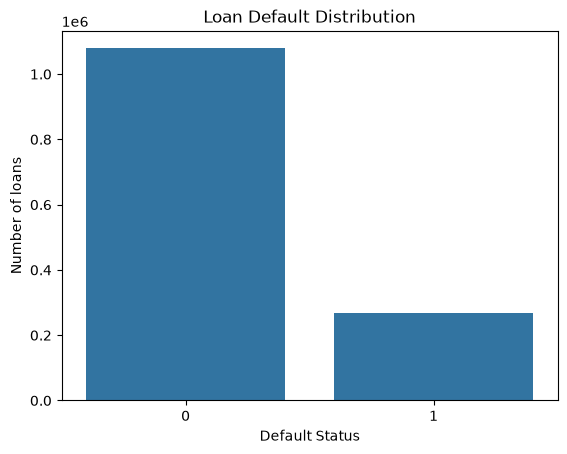

In [3]:
plt.Figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='Default'
)

plt.title('Loan Default Distribution')
plt.xlabel("Default Status")
plt.ylabel("Number of loans")

plt.show()

### 6.4 Numerical Feature Analysis

#### Business Question

What are the distributions and characteristics of the major numerical borrower and loan variables?

#### Numerical Variables

- `revenue`
- `dti_n`
- `loan_amnt`
- `fico_n`
- `experience_c`

#### Purpose

Understand the central tendency, spread, range, and potential extreme values of important numerical variables before examining their relationship with loan default.

#### Business Importance

Understanding the underlying distribution of borrower and loan characteristics provides context for identifying risk patterns and selecting appropriate transformations or features during feature engineering.

In [4]:
numerical_features = [
    "revenue",
    "dti_n",
    "loan_amnt",
    "fico_n",
    "experience_c"
]

numerical_summary = df[numerical_features].describe().T

numerical_summary

,count,mean,std,min,25%,50%,75%,max
revenue,1347681.0,77369.683174,70362.989597,1896.0,46600.00,65000.00,92000.00,10999200.00
dti_n,1347643.0,18.271438,9.861714,0.0,11.82,17.63,24.07,991.57
loan_amnt,1347681.0,14408.230490,8715.347372,500.0,7975.00,12000.00,20000.00,40000.00
fico_n,1347681.0,698.158922,31.848725,612.0,672.00,692.00,712.00,847.50
experience_c,1347681.0,0.999981,0.004307,0.0,1.00,1.00,1.00,1.00


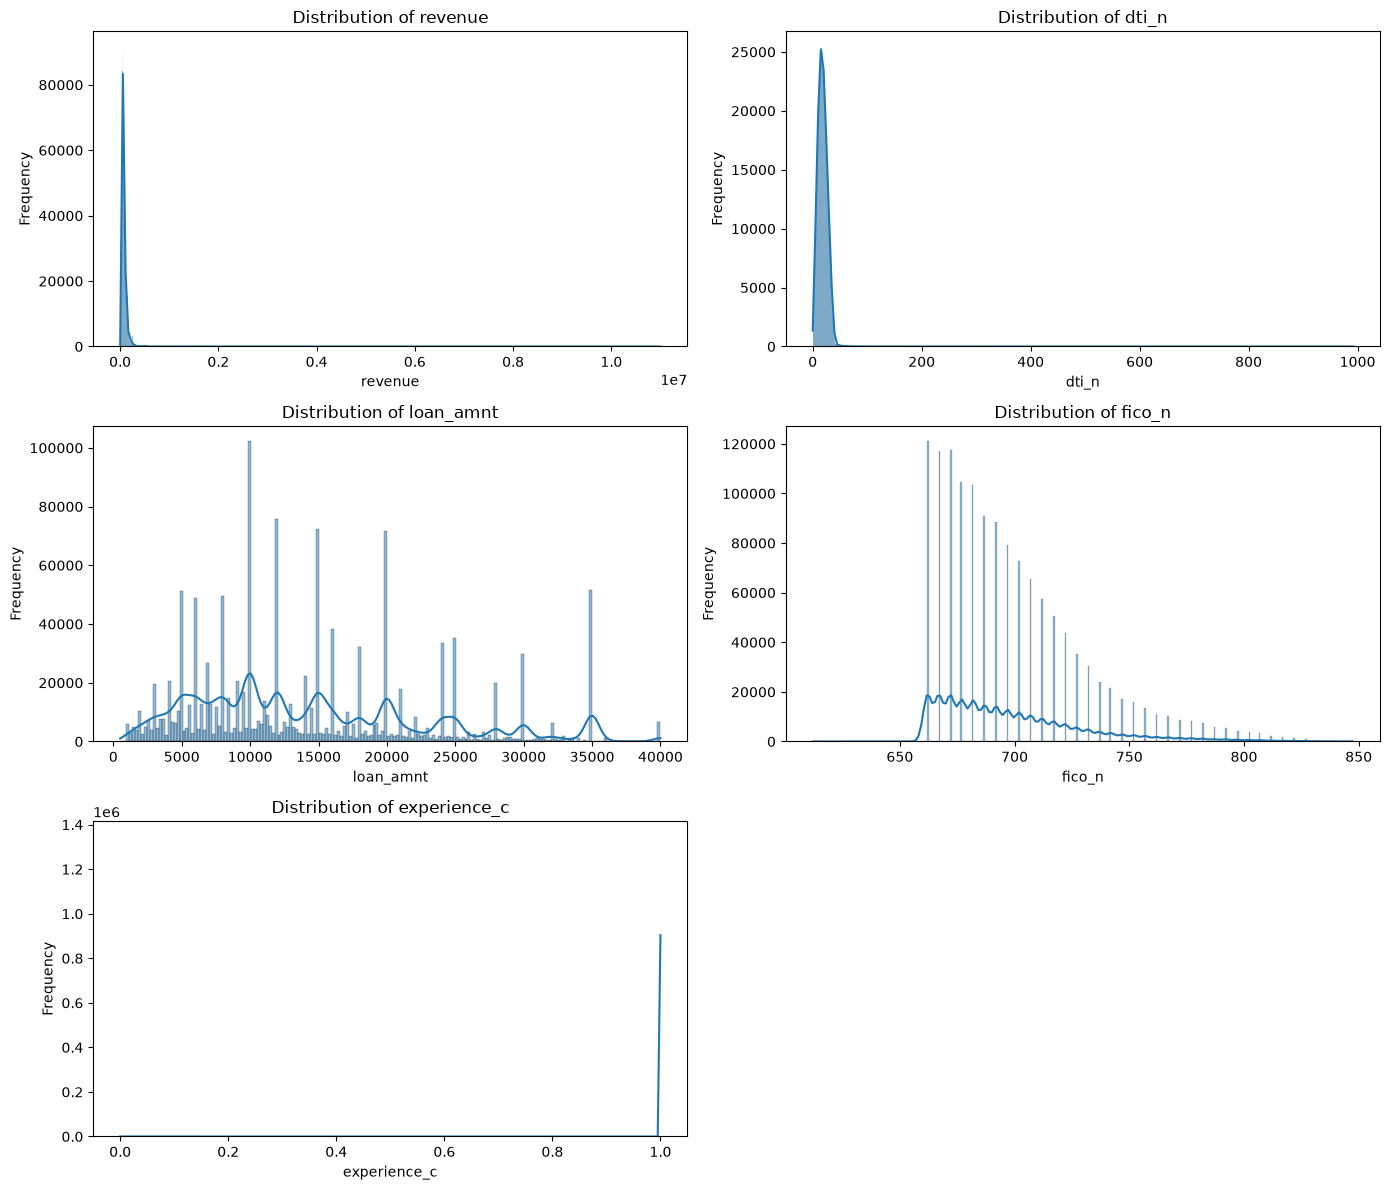

In [8]:
fig, axes = plt.subplots(3,2, figsize=(14,12))

for ax, feature in zip(axes.flatten(),numerical_features):
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

# Hide the unused sixth subplot
axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

#### Numerical EDA Findings

- `revenue` is strongly right-skewed, with most observations concentrated at lower values and a small number of very high-revenue observations.
- `dti_n` is strongly right-skewed and contains a long upper tail. The 38 anomalous `dti_n = 999` values were already handled during Phase 4.
- `loan_amnt` shows a discrete distribution with strong concentrations at commonly issued loan amounts and moderate right skew.
- `fico_n` is relatively concentrated, with most observations falling around the mid-to-high 600s and low 700s.
- `experience_c` is a binary feature with almost all observations equal to 1, indicating very low variation.

These observations describe the structure of the data but do not establish causal relationships with loan default. Relationships with the target variable will be examined in subsequent EDA sections.

### 6.5 Categorical Feature Analysis

#### Business Question

How is the loan portfolio distributed across important borrower, employment, ownership, and loan-purpose categories?

#### Categorical Variables

- `purpose`
- `emp_length`
- `home_ownership_n`
- `addr_state`

#### Purpose

Understand the composition of the loan portfolio and identify categories that may require further investigation for differences in default behavior.

#### Business Importance

Different borrower and loan categories may represent different levels of credit exposure and risk. Understanding their distribution provides context for later default-rate comparisons and risk segmentation.

In [9]:
purpose_count = df['purpose'].value_counts()

print('Loan Purpose Distribution')
print(purpose_count)

Loan Purpose Distribution
purpose
debt_consolidation    781206
credit_card           295551
home_improvement       87684
other                  78263
major_purchase         29543
medical                15606
small_business         15575
car                    14647
moving                  9520
vacation                9083
house                   7294
wedding                 2350
renewable_energy         936
educational              423
Name: count, dtype: int64


In [10]:
# defaulter in purpose

# Default counts and rates by loan purpose
purpose_def_count = (
    df.groupby('purpose')['Default']
      .agg(default_count='sum', loan_count='count', default_rate='mean')
      .sort_values('default_rate', ascending=False)
)

purpose_def_count

,default_count,loan_count,default_rate
purpose,,,
small_business,4650,15575,0.298555
renewable_energy,222,936,0.237179
moving,2229,9520,0.234139
house,1598,7294,0.219084
medical,3409,15606,0.218442
debt_consolidation,165258,781206,0.211542
other,16501,78263,0.210840
educational,88,423,0.208038
vacation,1743,9083,0.191897


### Loan Purpose Default Rate — Interpretation

- Debt consolidation is the largest loan-purpose category and represents a substantial share of the overall portfolio.
- Small business loans show the highest observed default rate at approximately 29.86%.
- Renewable energy and moving loans also show default rates above the overall portfolio default rate of 19.98%.
- Wedding and car loans show comparatively lower observed default rates.
- Default rate should be interpreted together with loan volume because categories with very small sample sizes may produce unstable estimates.
- These results indicate an association between loan purpose and observed default behavior, but they do not establish causation.

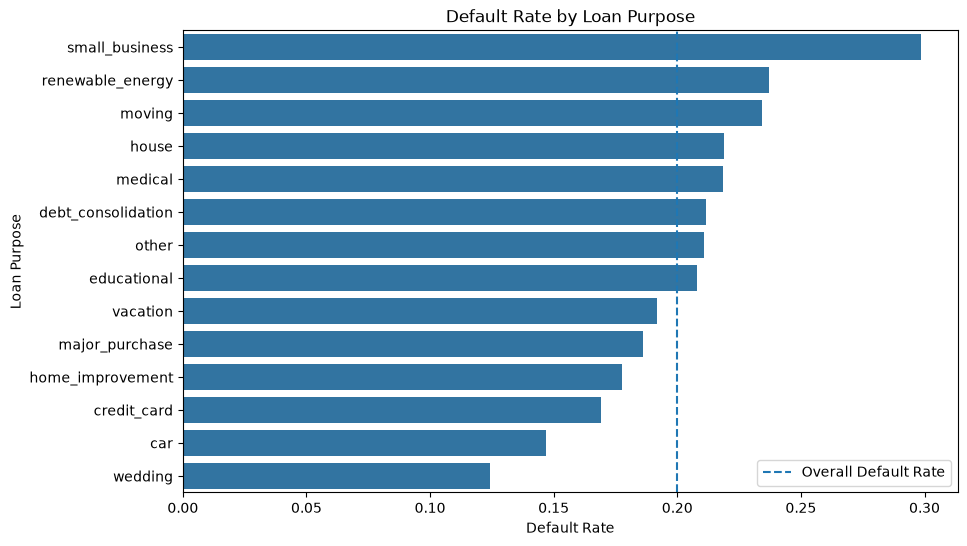

In [11]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=purpose_def_count,
    x='default_rate',
    y='purpose'
)

plt.axvline(
    df['Default'].mean(),
    linestyle='--',
    label='Overall Default Rate'
)

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Default Rate")
plt.ylabel("Loan Purpose")
plt.legend()

plt.show()

### Loan Purpose — EDA Conclusion

Loan purpose shows meaningful variation in observed default rates across categories. Small business loans have the highest observed default rate at approximately 29.86%, while wedding loans have the lowest at approximately 12.43%.

Several categories, including small business, renewable energy, moving, house, and medical, have default rates above the overall portfolio default rate of approximately 19.98%.

However, default rates should be evaluated together with loan volume because smaller categories may have less stable estimates. These findings indicate an association between loan purpose and default behavior but do not establish causation.